# JavaScript 基础第一天

基础语法

## 课程说明

本日先认识 JavaScript 怎样进入网页，再使用变量和常量保存数据、用算术运算处理数据，最后通过类型转换和模板字符串生成订单表格。学习目标是理解变量是存储数据的“容器”，知道本日五种基本数据类型，并能区分隐式转换和显式转换。

本篇依据[百度网盘课程资料](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)中的「JavaScript基础第一天」整理，提取码 `9987`。来源包括 109 页讲义、课堂代码、原课程 Markdown 笔记、XMind 和当天作业。正文跟随讲义顺序，代码保留原文件的变量、参数、缩进和启用/注释状态；来源中的疑点用“补充”就地说明。

除完整交互页面外，课堂代码通常摘录原 HTML 的 `<script>` 内容；把这些脚本放入一个 HTML 文件的 `<script>` 中，保存后用浏览器查看效果。代码均为 Markdown 示例，不在 Notebook 中执行。图片直接嵌入笔记。

## 1. JavaScript 介绍

### 1.1 JavaScript 是什么

JavaScript 是编程语言，本课程先学习它在浏览器中实现人机交互的用法。HTML 负责组织内容，CSS 负责外观，JavaScript 根据用户的行为让页面作出反馈。它的用途包括网页特效、表单验证、获取后台数据并渲染页面，也可以在 Node.js 环境中做服务端编程。

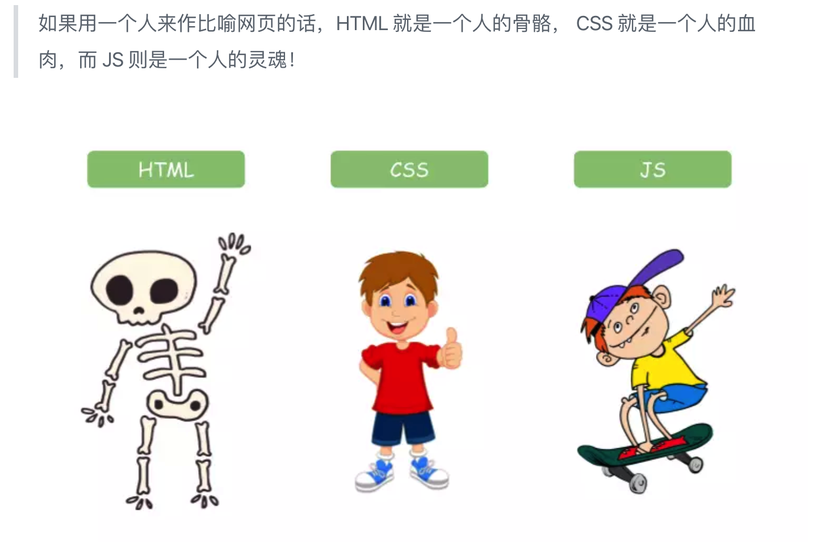

课程把 JavaScript 的知识分为基础语法和 Web APIs：

| 部分 | 作用 | 示例 |
| --- | --- | --- |
| ECMAScript | 规定语言的基础语法 | 变量、分支、循环、对象 |
| DOM | 文档对象模型，操作页面文档 | 移动元素、改变大小、添加或删除元素 |
| BOM | 浏览器对象模型，操作浏览器 | 页面弹窗、检测窗口宽度、存储数据 |

DOM 和 BOM 合称 Web APIs。本日主要学习基础语法，弹窗和页面输出作为体验使用。

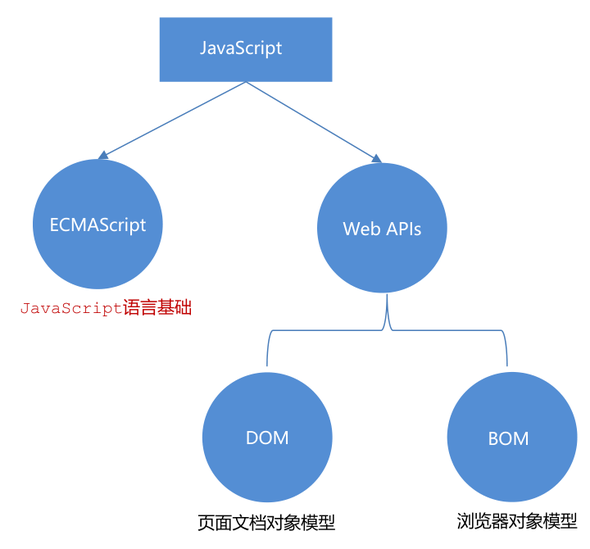

讲义提供的参考网站是 [MDN JavaScript 文档](https://developer.mozilla.org/zh-CN/docs/Web/JavaScript)。

### 初体验：点击按钮切换颜色

目标是感知三种技术怎样配合：HTML 提供四个按钮，CSS 的 `.pink` 决定粉色背景，JavaScript 在点击后把当前按钮变粉，取消之前按钮的粉色。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    .pink {
      background-color: pink;
    }
  </style>
</head>

<body>
  <button class="pink">按钮1</button>
  <button>按钮2</button>
  <button>按钮3</button>
  <button>按钮4</button>
  <script>
    let bts = document.querySelectorAll('button')
    for (let i = 0; i < bts.length; i++) {
      bts[i].addEventListener('click', function () {
        document.querySelector('.pink').className = ''
        this.className = 'pink'
      })
    }
  </script>
</body>

</html>
```

保存并打开该页面，点击不同按钮，应始终只有当前按钮显示粉色。这里出现的循环、事件和 DOM 方法先观察效果，后续课程再展开。

### 1.2 JavaScript 书写位置

**内部方式**：用 `<script>` 标签包裹代码。讲义建议写到 `</body>` 上方，因为浏览器按文档顺序加载 HTML；脚本若先运行，可能找不到它下方尚未加载的元素。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <!-- 内部js -->
  <script>
    // 页面弹出警示框
    alert('你好，js~')
  </script>
</body>

</html>
```

打开页面会弹出“你好，js~”。

**外部方式**：把代码写到 `.js` 文件，用 `<script src="...">` 引入。课堂示例的 HTML 与 `js` 文件夹在同一级：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script src="./js/my.js">
    // 中间不要写内容
  </script>
</body>

</html>
```

同目录下的 `js/my.js`：

```javascript
alert('我是外部的 js文件')
```

打开页面应弹出“我是外部的 js文件”。**使用 `src` 后，`script` 标签中间的代码不会执行**。外部脚本便于复用，也让 HTML 和脚本更容易维护。

**行内方式**：直接把代码写进标签属性，讲义这里只要求了解。

讲义示例：

```html
<body>
    <button onclick="alert('逗你玩~~~')">点击我月薪过万</button>
</body>
```

课堂练习：分别使用内部和外部方式，弹出“努力，奋斗”。把 `alert()` 的文字替换为该内容即可；外部文件只写 JavaScript，不再包一层 `<script>`。

**补充：**原 Markdown 笔记说 JavaScript 不能独立运行，这里是指本课的浏览器页面用法；前面的 Node.js 场景说明 JavaScript 也可以在其他运行环境中执行。

### 1.3 注释

注释用于添加说明或暂时屏蔽代码，被注释的内容不会执行。

| 类型 | 符号 | 忽略范围 | VS Code 快捷键 |
| --- | --- | --- | --- |
| 单行注释 | `//` | 符号右边这一行 | `Ctrl + /` |
| 块注释 | `/* ... */` | 两个符号之间的内容，可换行 | `Shift + Alt + A` |

按讲义语法整理的示例：

```javascript
// 单行说明
/*
  多行说明
  或暂时不执行的一段代码
*/
alert('你好，js')
```

### 1.4 结束符

英文分号 `;` 表示一条语句结束。讲义中的简单代码可以省略分号，浏览器会自动推断语句结束位置；书写时按团队要求统一风格。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    alert('你好')
    alert('我很好')
  </script>
</body>

</html>
```

会先后弹出“你好”和“我很好”，关闭前一个弹窗后才继续到下一句。

### 1.5 输入和输出语法

语法就是人与计算机打交道的规则。输入是把信息交给程序，输出是程序把处理结果展示出来。

| 语句 | 显示位置与用途 |
| --- | --- |
| `document.write(内容)` | 向页面 `body` 输出；内容含 HTML 标签时会解析成元素 |
| `alert(内容)` | 弹出警告对话框 |
| `console.log(内容)` | 在开发者工具的 Console 控制台输出，供程序员调试 |
| `prompt(提示文字)` | 弹出输入框，等待用户填写内容 |

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>

  <script>
    // 1. 文档输出内容
    document.write('我是div标签')
    document.write('<h1>我是标题</h1>')
    // 2. 控制台打印输出 给 程序员
    console.log('看看对不对')
    console.log('日志')
    // 3. 输入语句
    prompt('请输入您的年龄：')
  </script>
</body>

</html>
```

本例会显示输入框；关闭弹窗后页面包含普通文字和一级标题，控制台可看到“看看对不对”和“日志”。这段代码尚未保存输入值，因此输入年龄不会自动显示出来，后面的变量章节解决这个问题。

课程说明脚本按 HTML 文档流顺序执行。`alert()` 和 `prompt()` 等待用户响应时会影响页面显示，先出现弹窗不代表后面的脚本已经执行；详细执行过程留到后续学习。

课堂练习按要求依次使用：

```javascript
alert('你好 JS~')
document.write('JavaScript 我来了!')
console.log('它~会魔法吧~')
```

**补充：**原 Markdown 中的 `document.wirte` 是拼写错误，正确方法是 `document.write`；它向网页写入内容，`alert()` 才是弹窗输出。

### 1.6 字面量

字面量是在代码中直接写出的数据。例如 `1000` 是数字字面量，`'黑马程序员'` 是字符串字面量，`[]` 是数组字面量，`{}` 是对象字面量。后面通过变量来保存和使用它们。

## 2. 变量

### 2.1 为什么需要变量

用户填写姓名后，程序需要记住它才能再次输出。变量是计算机中存储数据的“容器”，类似有名字的盒子；**变量是容器，变量中的值才是数据**。

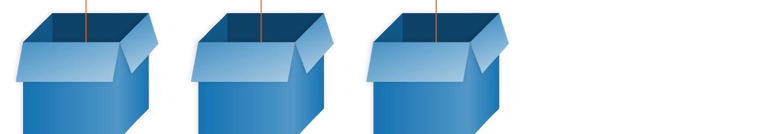

### 2.2 声明、赋值与初始化

声明是先创建变量，用关键字 `let` 加变量名；赋值是用 `=` 把右侧数据放入左侧变量。这里的 `=` 表示赋值，不是数学中的“相等”。

讲义写法：

```javascript
// 1. 声明变量
let age
// 2. 赋值
age = 18
// 3. 通过变量名取得数据
alert(age)
```

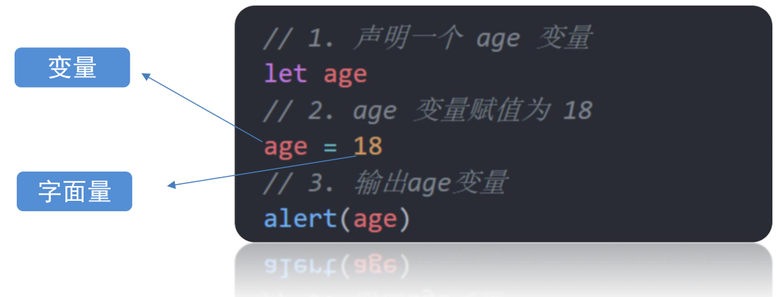

也可以同时声明并赋值，这叫**初始化**：`let age = 18`。课堂代码保留了分步写法的注释，并用两个变量完成练习：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1. 声明一个年龄变量
    // let age
    // // 2. 赋值   =  赋值
    // age = 18
    // console.log(age)
    // 3. 声明的同时直接赋值  变量的初始化
    // let age = 18
    // 小案例
    let num = 20
    let uname = 'pink老师'
    console.log(num)
    console.log(uname)
  </script>
</body>

</html>
```

控制台应显示 `20` 和 `pink老师`。讲义同一练习中姓名用“张三”，配套代码用“pink老师”，练习重点都是变量保存数值与姓名。

### 2.3 更新变量与声明多个变量

赋值后可以更新值，例如先 `let age = 18`，再 `age = 19`。更新时不能再加 `let` 重复声明同名变量。

多个变量可以用逗号分隔声明，但课程推荐**一行声明一个变量**，便于阅读：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>

    // 1 声明的同时直接赋值  变量的初始化
    // let age = 18
    // age = 19
    // // let age = 19
    // console.log(age)
    // 2. 声明多个变量    
    // let age = 18, uname = '迪丽热巴'
    // console.log(age, uname)
    // 提倡声明的方式
    let age = 19
    let uname = '迪丽热巴'
    console.log(age, uname)
  </script>
</body>

</html>
```

当前启用的代码输出 `19` 和“迪丽热巴”。注释里的更新示例与逗号声明示例用于对比，没有一起执行。

### 输入用户名案例

1. 输入：`prompt()` 获取姓名。
2. 保存：变量 `uname` 接收返回值。
3. 输出：`document.write(uname)` 写到页面。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 输出用户名案例
    // 1. 用户输入
    // prompt('请输入姓名')
    // 2. 内部处理保存数据
    let uname = prompt('请输入姓名')
    // 3. 打印输出
    document.write(uname)
  </script>
</body>

</html>
```

例如输入“张三”并确认，页面应显示“张三”。

### 2.4 交换两个变量的值

讲义需求是交换 `num1 = 10` 与 `num2 = 20`，课堂代码用两个人名演示同一过程。直接先把 `num2` 赋给 `num1` 会覆盖原来的 `num1`，所以需要临时变量 `temp` 保留它。

步骤：先 `temp = num1`，再 `num1 = num2`，最后 `num2 = temp`。赋值始终是把右边交给左边。

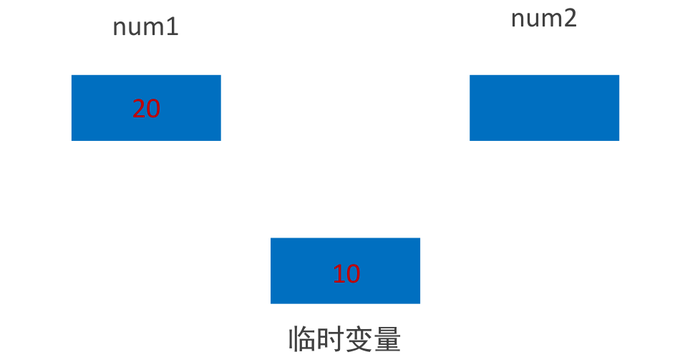

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // let if = 10
    let num1 = 'pink老师'
    let num2 = '戚薇'
    let temp
    // 都是把右边给左边
    temp = num1
    num1 = num2
    num2 = temp
    console.log(num1, num2)
  </script>
</body>

</html>
```

控制台应依次输出“戚薇”和“pink老师”。临时变量完成中转即可，不需要写额外的清理代码。

### 2.5 变量的本质与命名

内存是计算机存储数据的空间。课程把变量解释成程序在内存中申请的一块用于存放数据的小空间：

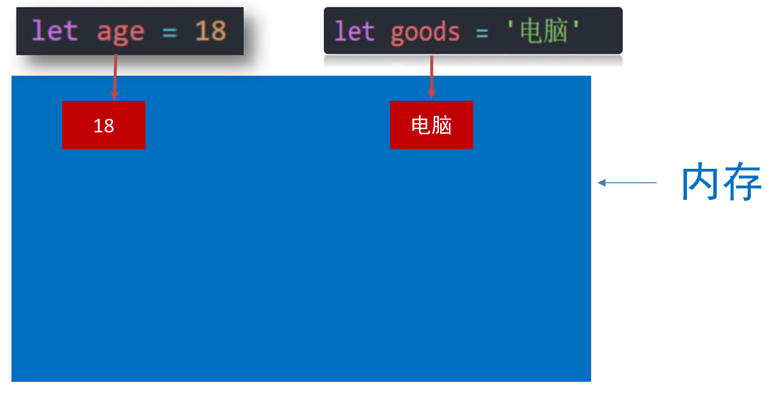

命名分为必须遵守的规则和建议遵守的规范：

| 类别 | 要求 |
| --- | --- |
| 规则 | 不能使用关键字，如 `let`、`var`、`if`、`for`；课程要求名字由字母、数字、下划线、`$` 组成，数字不能开头 |
| 规则 | 严格区分大小写，`age` 与 `Age` 是两个变量 |
| 规范 | 名字有意义，见名知义；推荐小驼峰，如 `userName` |

课堂代码中不合法的写法已经被注释：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // let if = 10
    let num1$_ = 11
    // let nav-bar = 11
    // let 1num = 10
    let pink = '老师'
    let Pink = '演员'
    console.log(pink, Pink)
  </script>
</body>

</html>
```

命名练习的结论：

| 名字 | 是否合法 | 原因或规范 |
| --- | --- | --- |
| `21age` | 否 | 数字开头 |
| `_age`、`$age` | 是 | 可以使用下划线、`$` |
| `user-name`、`na@me` | 否 | 包含这里不允许的字符 |
| `username` | 是 | 讲义多词命名练习推荐 `userName` |
| `userName` | 是 | 小驼峰 |
| `let` | 否 | 关键字 |

### 输出姓名、年龄、性别练习

依次用三个输入框获取数据，分别保存到 `uname`、`age`、`gender`，再输出到网页：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1. 姓名
    let uname = prompt('请输入姓名')
    let age = prompt('请输入年龄')
    let gender = prompt('请输入性别')
    document.write(uname, age, gender)
  </script>
</body>

</html>
```

本例一次把三个值交给 `document.write()`，原代码没有附加空格或标签，因此页面中三段内容会直接相连。

### 2.6 `let` 与 `var` 的区别

较早的 JavaScript 使用 `var` 声明变量。它允许同一变量重复声明，声明可能被提升，也没有 `let` 的块级作用域约束。本日优先使用 `let`，遇到旧项目再辨认 `var` 的行为；作用域和提升后续再详细学习。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // var num
    // console.log(num)
    // num = 10
    // num = 10
    // console.log(num)
    // var num
    // var num = 10
    // var num = 20
    // console.log(num)
    // num = 10
    // console.log(num)
    // let num
    // let num = 20
    // let num = 10
    // console.log(num)
  </script>
</body>

</html>
```

这份课堂文件全部是注释，直接打开不会输出结果。比较不同写法时，分别观察一组示例，不要把互相冲突的重复声明全部启用。

### 2.7 数组的基本使用

保存一个班级的多个人名时，逐个声明变量不方便。数组是一组按顺序保存的数据，可以放在一个变量名下，用 `[]` 表示。

| 术语 | 含义 |
| --- | --- |
| 元素 | 数组中保存的每个数据 |
| 下标 / 索引 | 元素的编号，从 `0` 开始 |
| 长度 | 元素的个数，通过 `数组名.length` 获取 |

声明数组使用 `let 数组名 = [值1, 值2, ...]`，取值使用 `数组名[下标]`。数组可以保存不同类型的数据。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // let arr = [10, 20, 30]
    // 1. 声明数组 有序 
    let arr = ['刘德华', '张学友', '黎明', '郭富城', 'pink老师', 10]
    // 2. 使用数组  数组名[索引号] 从0
    // console.log(arr)
    console.log(arr[0]) // 刘德华
    console.log(arr[4])
    // 3. 数组长度 =  索引号 + 1 
    console.log(arr.length)  // 6

    // let 刘德华 = 10
    // console.log(刘德华)
  </script>
</body>

</html>
```

本例输出“刘德华”、“pink老师”和长度 `6`。最后一个元素的索引是 `5`，不要把元素个数 `6` 当作最后一个索引。

**补充：**原代码的“数组长度 = 索引号 + 1”在这里是指**最后一个索引 + 1**。对于本例这种从 `0` 起连续排列的数组，长度是 `6`。

课堂数组取值练习：定义星期一到星期日七个元素，输出星期日。根据题目整理：

```javascript
let week = ['星期一', '星期二', '星期三', '星期四', '星期五', '星期六', '星期日']
console.log(week[6])
```

## 3. 常量

使用 `const` 声明的变量称为常量，适合不需要重新赋值的数据。命名规则与变量一致，必须在声明时初始化，也不能重复声明或重新赋值。

讲义写法：

```javascript
const PI = 3.14
console.log(PI)
```

课堂文件把错误演示保留为注释：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1.常量 不允许更改值
    // const PI = 3.14
    // console.log(PI)
    // PI = 3.15
    // console.log(PI)
    // 2. 常量声明的时候必须赋值
    // const PI 
  </script>
</body>

</html>
```

其中 `PI = 3.15` 是对常量重新赋值，`const PI` 是没有初始化；分别会产生错误。本日先记住 `const` 的约束针对重新赋值。

| 声明方式 | 本日使用建议 |
| --- | --- |
| `let` | 需要更新值的变量 |
| `const` | 不需要重新赋值的数据 |
| `var` | 阅读旧代码时识别，当前课程不作为首选 |

## 4. 数据类型

### 4.1 数据分类与数字类型

程序处理的数据包括价格、姓名、是否成立等不同含义。分类有助于使用数据，也有助于理解存储方式。讲义分为基本数据类型和引用数据类型，本日重点学习以下五种基本类型：

| 类型 | 含义 | 示例 |
| --- | --- | --- |
| `number` | 数字，包括正数、负数、整数、小数 | `100`、`-40`、`12.345` |
| `string` | 字符串 | `'小明'`、`'123'`、`''` |
| `boolean` | 布尔值，肯定或否定 | `true`、`false` |
| `undefined` | 未定义，常见于声明后未赋值 | `let value` 中的值 |
| `null` | 空值 | `let obj = null` |

对象属于引用数据类型，后续再展开。这里是**本日讲解范围**，不把表格当作 JavaScript 所有类型的完整清单。

JavaScript 不要求声明时写死变量类型，当前保存的值决定当前数据的类型；讲义用“弱数据类型”与 Java 的 `int num = 10` 对比。

### 算术运算符与优先级

| 运算符 | 含义 | 本日示例 |
| --- | --- | --- |
| `+` | 加 | `1 + 1` 得 `2` |
| `-` | 减 | `3 - 1` 得 `2` |
| `*` | 乘 | `2 * 3` 得 `6` |
| `/` | 除 | `5 / 2` 得 `2.5` |
| `%` | 取余 | `5 % 3` 得 `2`，`3 % 5` 得 `3` |

`%` 常用来判断能否整除。乘、除、取余优先级相同，高于加、减；本日这些算术运算在同一优先级下从左到右计算，有括号先算括号内。

讲义的优先级练习：

```javascript
console.log(1 + 2 * 3)     // 7
console.log(10 - 8 / 2)    // 6
console.log(2 % 5 + 4 * 2) // 10
```

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // js 弱数据类型的语言 只有当我们赋值了，才知道是什么数据类型
    // let num = 'pink'
    // let num = 10.11
    // console.log(num)
    console.log(1 + 1)
    console.log(1 * 1)
    console.log(1 / 1)
    console.log(4 % 2) // 求余数
    console.log(5 % 3) // 求余数  2 
    console.log(3 % 5) // 求余数  3 
    // java 强数据类型的语言    int num = 10

    console.log('pink老师' - 2)
    console.log(NaN - 2)
    console.log(NaN + 2)
    console.log(NaN / 2)
    console.log(NaN === NaN)
  </script>
</body>

</html>
```

`NaN` 是 `Not a Number`，表示无法得到有效数字的结果。例如文字减数字不能形成有效数学运算。原例中 `'pink老师' - 2` 得 `NaN`，后面 `NaN` 的加减除运算也得 `NaN`；`NaN === NaN` 得 `false`。`NaN` 自身仍属于 `number`。

### 4.2 计算圆的面积案例

需求：输入圆的半径，计算面积并显示到网页。

1. `prompt()` 获取半径，存入 `r`。
2. 数学公式 `π × r²` 转成 JavaScript 的 `3.14 * r * r`。
3. 把计算结果存到 `re`，用 `document.write()` 输出。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1. 页面弹出输入框
    let r = prompt('请输入圆的半径：')
    // 2. 计算圆的面积（内部处理）
    let re = 3.14 * r * r
    // 3. 页面输出
    document.write(re)

    // NaN   not a number 
  </script>
</body>

</html>
```

例如输入半径 `2`，按本例 `3.14` 计算，面积为 `12.56`。虽然输入是字符串，乘法会自动转换可转换的数字文本，后面的类型转换章节解释这个行为。

### 4.3 字符串与拼接

用单引号、双引号或反引号包裹的数据是字符串。`11` 是数字，`'11'` 是字符串；`''` 是空字符串，`'str'` 是文字而不是变量 `str` 的值。

引号要成对，单、双引号可互相嵌套，必要时用反斜杠 `\` 转义同类引号。课堂代码保留了这些不同写法：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // let str = 'pink'
    // let str1 = "pink"
    // let str2 = `中文`
    // console.log(str2)
    // console.log(11)
    // console.log(`11`)
    // console.log(str)
    // console.log('str')
    // console.log('pink老师讲课非常有"基情"')
    // console.log("pink老师讲课非常有'基情'")
    // console.log('pink老师讲课非常有\'基情\'')
    // 字符串拼接
    // console.log(1 + 1)
    // console.log('pink' + '老师')

    let age = 25

    // document.write('我今年' + 19)
    // document.write('我今年' + age)
    // document.write('我今年' + age + '岁了')
    document.write('我今年' + age + '岁了')


  </script>
</body>

</html>
```

当前启用部分把变量 `age = 25` 拼入字符串，页面应显示“我今年25岁了”。记住“数字相加，字符相连”：`1 + 1` 是加法，`'pink' + '老师'` 是拼接。

**补充：**原 Markdown 示例中的 `documeent.write` 同样是拼写错误；此处使用正确的 `document.write`。

### 4.4 模板字符串

拼接多个变量时，连续写 `+` 容易混淆引号。模板字符串在外面使用反引号，内部用 `${变量名}` 插入变量；也支持换行，后面用它编写整段表格。

反引号在英文输入状态下位于键盘 `Tab` 上方、数字 `1` 左侧，不是单引号。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // let age = 20
    // // 模板字符串 外面用`` 里面 ${变量名}
    // document.write(`我今年${age}岁了`)
    let uname = prompt('请输入您的姓名:')
    let age = prompt('请输入您的年龄:')
    // 输出
    document.write(`大家好，我叫${uname}， 我今年贵庚${age}岁了`)
  </script>
</body>

</html>
```

本例依次输入姓名、年龄，再把两者放到一句话里。比如姓名“张三”、年龄“18”，按原代码显示“大家好，我叫张三， 我今年贵庚18岁了”。

### 4.5 布尔、未定义与空值

布尔类型只有 `true` 和 `false`，用于表达真或假，例如比较 `3 > 4` 得 `false`。

只声明变量而没有赋值时，默认值是 `undefined`；程序可以借它判断某个值是否尚未传入。`null` 是主动赋予的空值，常用于将来要存放对象、但对象还没有准备好的变量。

| 对比 | `undefined` | `null` |
| --- | --- | --- |
| 本日含义 | 没有赋值 | 已赋值，但值为空 |
| 示例 | `let num` | `let obj = null` |
| 本例与 `1` 相加 | `NaN` | `1` |

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1. true  false 是布尔型字面量  
    // console.log(3 > 4)
    // let isCool = false
    // console.log(isCool)
    // 2. 未定义类型   弱数据类型   声明一个变量未赋值就是 undefined
    // let num
    // console.log(num)
    // 3. null 空的
    // let obj = null
    // console.log(obj)
    // 计算有区别
    console.log(undefined + 1)  // NaN
    console.log(null + 1) // 1
  </script>
</body>

</html>
```

前三组类型演示是注释，当前实际执行的是最后两行，用于对比 `undefined` 和 `null` 的运算结果。

### 4.6 检测数据类型

`typeof` 返回被检测数据的类型名称。`typeof x` 和 `typeof(x)` 得到相同结果，课程常用不加括号的形式。控制台中数据颜色可以帮助观察，但颜色随浏览器变化，类型应通过 `typeof` 确认。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    let num = 10
    console.log(typeof num)
    let str = 'pink'
    console.log(typeof str)
    let str1 = '10'
    console.log(typeof str1)
    let flag = false
    console.log(typeof flag)
    let un
    console.log(typeof (un))
    let obj = null
    console.log(typeof obj)


    let num1 = prompt('请输入第一个数：')
    console.log(typeof num1)
  </script>
</body>

</html>
```

| 本例变量 | 值 | `typeof` 的结果 |
| --- | --- | --- |
| `num` | `10` | `'number'` |
| `str`、`str1` | `'pink'`、`'10'` | `'string'` |
| `flag` | `false` | `'boolean'` |
| `un` | `undefined` | `'undefined'` |
| `obj` | `null` | `'object'` |

最后的输入框即使输入 `10`，确认后 `typeof num1` 仍为 `'string'`，这正是下一章需要类型转换的原因。

**补充：**`typeof` 始终是运算符，`typeof(x)` 只是给被检测值加括号；讲义称它为“函数形式”是对外形的说明。`typeof null` 返回 `'object'` 是 JavaScript 的历史行为，不能据此把 `null` 改归为引用类型。

## 5. 类型转换

### 5.1 为什么需要转换

表单和 `prompt()` 确认得到的内容默认是字符串。输入两个数后直接用 `+`，结果可能成为文字拼接，而不是期望的加法。类型转换就是把当前数据转换成程序所需的另一种类型。

**补充：**`prompt()` 点击“取消”时返回 `null`。本日案例按用户填写并确认的课堂流程说明。

### 5.2 隐式转换

某些运算符执行时，系统自动转换数据类型，这叫隐式转换。本日先掌握下面的规则：

- 二元 `+` 两边只要有一边是字符串，就做字符串拼接。
- `-`、`*`、`/`、`%` 等算术运算会把这里的数字字符串转换为数字；无法转换时产生 `NaN`。
- 一元 `+` 是正号，可把可转换的字符串转成数字，例如 `+'123'`。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    console.log(1 + 1)
    console.log('pink' + 1)
    console.log(2 + 2)
    console.log(2 + '2') // 22
    console.log(2 - 2)
    console.log(2 - '2')  // 0  
    console.log(+12)
    console.log(+'123')  // 转换为数字型
  </script>
</body>

</html>
```

按原顺序，结果为 `2`、`'pink1'`、`4`、`'22'`、`0`、`0`、`12`、`123`。特别区分 `2 + '2'` 与 `2 - '2'`。

### 5.3 显式转换为数字

显式转换是主动写代码告诉程序要转成什么类型。相比依赖隐式转换，代码目的更明确。

| 写法 | 当前用途 | 边界 |
| --- | --- | --- |
| `Number(数据)` | 把整个值转成数字 | `'123'` 可转换；`'pink'`、`'12px'` 得 `NaN` |
| `parseInt(数据)` | 解析数字开头的整数部分 | `'12.94px'` 得 `12`，不做四舍五入 |
| `parseFloat(数据)` | 解析数字开头的小数部分 | `'12.94px'` 得 `12.94` |

`parseInt()` 和 `parseFloat()` 遇到数字之后的非数字内容时停止解析；如果一开始就没有可解析的数字，会得到 `NaN`。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    .box {
      width: 50px;
      height: 50px;
    }
  </style>
</head>

<body>
  <script>
    let str = '123'
    console.log(Number(str))
    console.log(Number('pink'))
    // let num = Number(prompt('输入年薪'))
    // let num = +prompt('输入年薪')
    // console.log(Number(num))
    // console.log(num)
    console.log(parseInt('12px'))
    console.log(parseInt('12.34px'))
    console.log(parseInt('12.94px'))
    console.log(parseInt('abc12.94px'))

    // -------------------
    console.log(parseFloat('12px')) // 12
    console.log(parseFloat('12.34px')) // 12.34
    console.log(parseFloat('12.94px')) // 12.94
    console.log(parseFloat('abc12.94px')) // 12.94
  </script>
</body>

</html>
```

| 原例输入 | `Number` | `parseInt` | `parseFloat` |
| --- | --- | --- | --- |
| `'123'` | `123` | `123` | `123` |
| `'12px'` | `NaN` | `12` | `12` |
| `'12.34px'` | `NaN` | `12` | `12.34` |
| `'12.94px'` | `NaN` | `12` | `12.94` |
| `'abc12.94px'` | `NaN` | `NaN` | `NaN` |

**补充：**原代码最后一行 `parseFloat('abc12.94px')` 的注释写成 `12.94`，实际结果是 `NaN`，因为字符串开头的 `abc` 不能解析为数字。上面的原代码保留该注释，结果表给出正确行为。原文件名“显示转换”对应的术语应为“显式转换”。

### 5.4 显式转换为字符串

讲义还介绍了 `String(数据)` 与 `变量.toString(进制)` 两种写法。

根据讲义语法整理的示例：

```javascript
let num = 10
console.log(String(num))     // '10'
console.log(num.toString())  // '10'
console.log(num.toString(2)) // '1010'
```

`String()` 明确把值变成字符串。数字的 `toString()` 可传进制，不传时按十进制。

**补充：**`null` 和 `undefined` 不能直接调用 `.toString()`；需要转换这些值时可用 `String(null)`、`String(undefined)`。

### 5.5 两数求和案例

1. 用两个 `prompt()` 获取输入。
2. 用一元 `+` 转成数字；也可以写 `Number(prompt(...))`。
3. 相加后用模板字符串组织结果，输出。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1. 用户输入   prompt 得到是字符串类型 要转换为 数字型
    let num1 = +prompt('请输入第一个数字：')
    let num2 = +prompt('请输入第二个数字：')
    // 2. 输出
    alert(`两个数相加的和是:${num1 + num2}`)
  </script>
</body>

</html>
```

输入 `2`、`3` 应弹出“两个数相加的和是:5”。讲义练习要求输出到页面，配套代码用 `alert()` 展示；练习页面输出时可把最后一行改成 `document.write(...)`，计算过程相同。

## 6. 综合案例：渲染用户订单信息

需求：用户填写商品价格、数量和收货地址，程序自动计算总价，并在页面上生成订单表格。

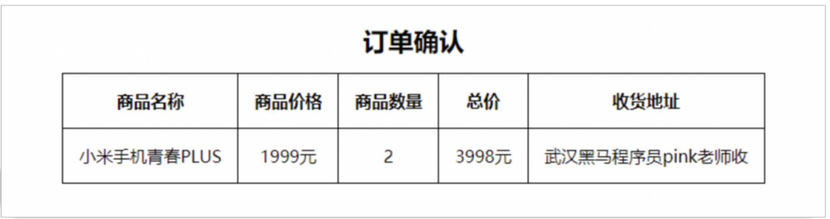

### 6.1 先写流程

1. 三个输入值分别保存在 `price`、`num`、`address`。
2. 价格、数量参与计算，因此输入后转为数字；地址保持字符串。
3. `total = price * num` 计算总价。
4. 模板字符串编写表格，把变量插入各个 `td`。
5. `document.write()` 将这段 HTML 写到页面，浏览器解析为表格。

### 6.2 完整课堂页面

目标文件为 `02-code/24-综合案例.html`。`h2` 居中，表格合并边框并通过 `margin: 0 auto` 居中，单元格有边框；这部分沿用之前学习的 HTML 和 CSS。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    h2 {
      text-align: center;
    }

    table {
      /* 合并相邻边框 */
      border-collapse: collapse;
      height: 80px;
      margin: 0 auto;
      text-align: center;
    }

    th {
      padding: 5px 30px;
    }

    table,
    th,
    td {
      border: 1px solid #000;
    }
  </style>
</head>

<body>
  <h2>订单确认</h2>


  <script>
    // 1 用户输入
    let price = +prompt('请输入商品价格：')
    let num = +prompt('请输入商品数量：')
    let address = prompt('请输入收获地址：')
    // 2.计算总额
    let total = price * num
    // 3.页面打印渲染
    document.write(`
      <table>
          <tr>
            <th>商品名称</th>
            <th>商品价格</th>
            <th>商品数量</th>
            <th>总价</th>
            <th>收货地址</th>
          </tr>
          <tr>
            <td>小米青春版PLUS</td>
            <td>${price}元</td>
            <td>${num}</td>
            <td>${total}元</td>
            <td>${address}</td>
          </tr>
        </table>
    `)
  </script>
</body>

</html>
```

验证：依次输入价格 `1999`、数量 `2` 和一个收货地址，总价应为 `3998`。页面显示“订单确认”，商品名按源码是“小米青春版PLUS”，价格 `1999元`、数量 `2`、总价 `3998元`，最后一格是刚才填写的地址。

**补充：**讲义第 101 页分析混入了 Java 的 `Scanner` 和三位数拆分内容，与当前案例不一致；本节按第 102 页和实际课堂代码整理。源码提示“收获地址”是文字笔误，其变量用途仍是收货地址；代码保持原文。

## 7. 常见错误与复习路线

讲义最后用错误信息帮助定位原因：

| 报错或现象 | 排查方向 |
| --- | --- |
| `Missing initializer in const declaration` | `const` 声明时没有赋初值 |
| `age is not defined` | 变量未声明，或使用时变量名拼写与声明不一致 |
| `Identifier 'age' has already been declared` | 同一作用域重复声明了 `let` / `const` 变量 |
| `Assignment to constant variable` | 给常量重新赋值 |
| 输入 `2` 和 `3` 得到 `23` | `prompt()` 返回字符串；计算前用 `Number()` 或一元 `+` 转为数字 |

本日复习按原课安排：先用 XMind 或 Markdown 梳理知识点，再先写伪代码思路、独立重写两遍订单信息案例，之后完成测试题和当天作业。课程提供的复习测试是[讲义测试](https://ks.wjx.top/vj/h8kAn6p.aspx)，配套作业另有[客观题链接](https://ks.wjx.top/vm/YXyjrAe.aspx#)，可用于自行练习。

## 8. 配套作业

以下是第一天资料包内的作业，先独立完成再对照参考。宣传图片、扫码图和重复的输入截图不重复收录。

### 8.1 简答题与结果分析

1. 变量的使用场景：保存用户输入或中间结果，之后再读取和处理。
2. 本日五种基本数据类型：`number`、`string`、`boolean`、`undefined`、`null`。
3. 模板字符串：外层反引号，变量放在 `${变量名}` 中。
4. 下面三句输出什么？

```javascript
const num = 10
console.log(num + 11)
console.log(num + '11')
console.log(num + +'11')
```

根据题目分析，依次为数字 `21`、字符串 `'1011'`、数字 `21`。第三行先用一元 `+` 把 `'11'` 转成数字，再相加。

5. 下面三句输出什么？

```javascript
const num = 10
console.log(typeof num + '11')
console.log(typeof (num + '11'))
console.log(typeof (num + +'11'))
```

依次是 `'number11'`、`'string'`、`'number'`。第一行先取得类型字符串再拼接；后两行先算括号中的表达式，再检测结果类型。这里的答案是对原题的分析，未把它作为配套文件提供的执行输出。

### 8.2 获取用户信息与增加年龄

**获取用户信息**：依次询问姓名、年龄、性别，保存到变量，再在控制台输出。

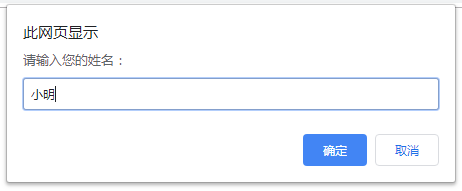

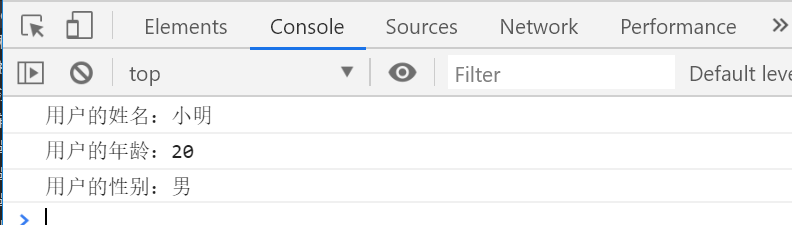

**增加年龄**：询问当前年龄，增加 `5` 岁，用弹窗提示五年后的年龄。关键是先把年龄转为数字，不要把 `'18' + 5` 写成字符串拼接。

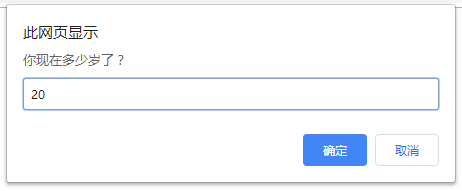

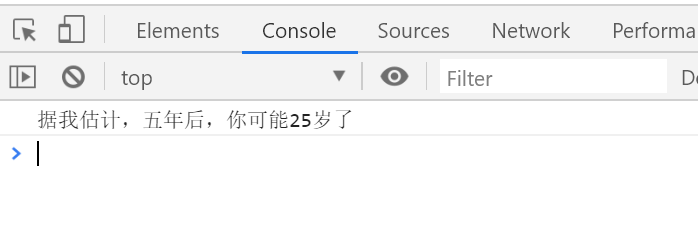

资料提供的 `05-作业/02-答案/作业答案参考.html` 将参考写法全部注释，用于对照阅读：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <title>Document</title>
</head>

<body>

    <script>
        // let username = prompt("输入姓名")
        // let age = prompt("输入年龄")
        // let sex = prompt("输入性别")

        // console.log('你的姓名是:' + username + '年龄:' + age + '性别:' + sex)
        // console.log(`你的姓名是:${username} 年龄: ${age}性别:${sex}`)



        //********************************

        // let res = prompt("请输入你的当前年龄")
        // console.log(typeof res)
        // 不要忘记转换为数字型
        // alert("你5年之后是：" + (Number(res) + 5))

        // 额外拓展作业部分
        // res = +'18' //就会转换为数字类型
        // console.log(typeof res)
        // let res = +prompt("请输入你的当前年龄")
        // alert("你5年之后是：" + (res + 5))
    </script>
</body>

</html>
```

分别练习时，只启用对应的一组。获取用户信息部分演示了普通拼接与模板字符串；年龄部分演示 `Number(res) + 5` 和 `+prompt(...)` 两种转换方式。

### 8.3 计算银行卡余额

需求：依次输入银行卡总额、水费、电费、网费，在网页中输出表格并显示剩余余额。

1. 准备总额、三项费用和余额这五个变量。
2. 获取四个输入值；第五个值通过计算得到。
3. 余额 = 总额 − 水费 − 电费 − 网费。
4. 用模板字符串把输入值和余额填入表格。

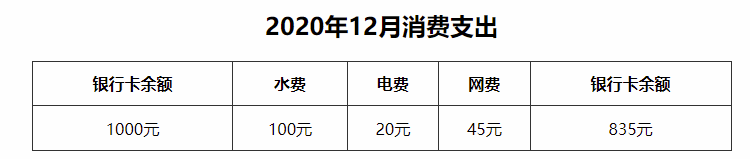

完整配套参考页面：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
    <style>
        h2 {
            text-align: center;
        }

        table {
            width: 700px;
            height: 90px;
            margin: 0 auto;
        }

        table,
        th,
        td {
            border: 1px solid #333;
            border-collapse: collapse;
            text-align: center;
        }
    </style>
</head>

<body>
    <h2>2020年12月消费支出</h2>

    <script>

        // 1. 声明5个变量 
        const total = prompt('请输入银行卡总额:')
        const waterBill = prompt('请输入水费:')
        const dianBill = prompt('请输入电费:')
        const netBill = prompt('请输入网费:')
        const money = total - waterBill - dianBill - netBill
        // console.log(money)
        document.write(`<table>
        <tr>
            <th>银行卡余额</th>
            <th>水费</th>
            <th>电费</th>
            <th>网费</th>
            <th>银行卡余额</th>
        </tr>
        <tr>
            <td>${total}元</td>
            <td>${waterBill}元</td>
            <td>${dianBill}元</td>
            <td>${netBill}元</td>
            <td>${money}元</td>
        </tr>
    </table>`)
    </script>
</body>

</html>
```

这里用 `const`，因为每个变量只赋值一次；减法会将可转换的输入字符串转成数字。原动画依次输入总额 `1000`、水费 `100`、电费 `20`、网费 `45`，计算余额为 `835`，表格应显示 `835元`。

**补充：**参考源码首列表头写“银行卡余额”，该列填的是初始总额；最后一列才是扣费后的余额。笔记保留源码，同时说明两列的含义。该练习与订单表格一样，重点是输入、处理、渲染三个步骤。